# MF — Esperimento isolato: bias globali vs personalizzazione fold-in

**Obiettivo.** Spiegare perché la baseline `mf_explicit_foldin` possa produrre ranking peggiori o meno personalizzati di Popularity in condizioni di *new-user cold-start*, senza modificare il benchmark ufficiale.

**Domande sperimentali (non assunzioni).**

1. **H1 — Discontinuità a k=1.** Nel notebook `recommendation_02`, a `k=0` viene usata Popularity, mentre già a `k=1` si passa interamente al punteggio MF. Quanto sono diverse le graduatorie **Popularity** e **soli bias MF**?
2. **H2 — Forza del fold-in.** Il termine personale `Q @ p_u` influenza realmente l'ordine degli item, oppure il ranking è quasi interamente spiegato da `item_bias`?
3. **H3 — Sparsità.** Gli item scarsamente osservati nel training (o mai osservati) contribuiscono a risultati instabili?

**Input:** esclusivamente il protocollo `rs_coldstart_full` già esportato e la configurazione del notebook 02. Nessun accesso a Qdrant, GTE, LLM o TMDb. Le statistiche sulla performance leggono il ground truth **solo dopo** avere costruito i ranking diagnostici, e solo sulla validation.

**Integrità del progetto:** questo notebook non modifica `src/`, i notebook precedenti, `predictions/ranking_results.csv` o i report ufficiali. Scrive solo in `evaluations/mf_foldin_diagnostic/` e non esegue tuning dei parametri. Il codice `ExplicitMF` sottostante è riportato *identico* dal notebook `recommendation_02_baselines_mf_gte(3).ipynb` allegato.

### Metodo e riferimenti

Per MF esplicita con bias il punteggio è

\[
  s_{MF}(u,i)=\mu+b_i+b_u+q_i^\top p_u.
\]

Per uno stesso utente, `b_u` è una costante e quindi non altera il ranking. Confrontiamo:

- **Popularity:** media dei rating con Bayesian shrinkage, come nel benchmark ufficiale.
- **MF solo bias:** `mu + item_bias` (nessuna personalizzazione).
- **MF completa:** `mu + item_bias + user_bias + Q @ user_vector` (con `fold_reg` già selezionato sulla validation).

Misuriamo ampiezza relativa dei contributi, intersezione delle Top-10 e copertura degli item (oltre a metriche A di controllo sulla validation). **La deviazione standard dei punteggi non implica da sola il peso effettivo sui primi posti:** va letta insieme alla sovrapposizione delle Top-10.

**Riferimenti:** Koren, Bell & Volinsky (2009), *Matrix Factorization Techniques for Recommender Systems*, IEEE Computer 42(8), 30–37, DOI: 10.1109/MC.2009.263; Cañamares & Castells (2018), *Should I Follow the Crowd? A Probabilistic Analysis of the Effectiveness of Popularity in Recommender Systems*, SIGIR, DOI: 10.1145/3209978.3210014. Questi lavori motivano l'analisi, ma non dimostrano a priori le ipotesi H1–H3 sul nostro codice.

## 0. Configurazione e percorsi

Il notebook trova automaticamente la root partendo dalla cartella `notebooks/`. Se necessario, imposta `PROJECT_ROOT_OVERRIDE`.

**Riutilizzo dei pesi:** il notebook 02 non salva `Q` né `item_bias`, quindi i soli CSV di ranking non consentono la decomposizione esatta. Alla prima esecuzione questa diagnostica riesegue **soltanto il training MF originale** e salva una cache isolata; nelle esecuzioni successive riutilizza quei pesi se i dati e gli iperparametri non sono cambiati. In nessun caso riesegue GTE o gli altri esperimenti.

In [1]:
from pathlib import Path
import hashlib
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT_OVERRIDE = None  # es. Path('/Users/.../progetto')
PROTOCOL_ID = 'rs_coldstart_full'
TOP_K = 10
POS_MIN = 4.0
DIAGNOSTIC_SPLIT = 'validation'   # volutamente solo validation
SAVE_DIAGNOSTICS = True
MAX_DETAIL_ROWS = 12

def find_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        return Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
    for p in [Path.cwd().resolve(), *list(Path.cwd().resolve().parents)[:6]]:
        if (p/'datasets/processed/recommendation_protocol'/PROTOCOL_ID/'protocol_manifest.json').is_file():
            return p
    raise FileNotFoundError('Protocollo non trovato: imposta PROJECT_ROOT_OVERRIDE')

ROOT = find_root()
BASE = ROOT/'datasets'/'processed'/'recommendation_protocol'/PROTOCOL_ID
INPUTS = BASE/'inputs'
PRIVATE = BASE/'private_evaluation'
PRED = BASE/'predictions'
EXPERIMENT = BASE/'evaluations'/'mf_foldin_diagnostic'
OFFICIAL_CONFIG = BASE/'evaluations'/'baseline_mf_gte'/'model_config.json'
MODEL_CACHE = EXPERIMENT/'mf_state.npz'

manifest = json.loads((BASE/'protocol_manifest.json').read_text(encoding='utf8'))
config = json.loads(OFFICIAL_CONFIG.read_text(encoding='utf8'))
assert manifest['protocol_id'] == config['protocol_id'] == PROTOCOL_ID
SEED = int(config['seed'])
MF_RANK = int(config['mf_rank'])
MF_EPOCHS = int(config['mf_epochs'])
MF_LR = float(config['mf_lr'])
MF_REG = float(config['mf_reg'])
FOLD_REG = float(config['mf_fold_reg_selected'])
POPULARITY_PRIOR = float(config['popularity_prior'])
print('Protocollo:', BASE)
print('Esperimento isolato:', EXPERIMENT)
print('Configurazione MF:', {'seed':SEED,'rank':MF_RANK,'epochs':MF_EPOCHS,
      'lr':MF_LR,'reg':MF_REG,'fold_reg':FOLD_REG,'popularity_prior':POPULARITY_PRIOR})

Protocollo: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_protocol/rs_coldstart_full
Esperimento isolato: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_protocol/rs_coldstart_full/evaluations/mf_foldin_diagnostic
Configurazione MF: {'seed': 20261021, 'rank': 24, 'epochs': 18, 'lr': 0.008, 'reg': 0.06, 'fold_reg': 1.0, 'popularity_prior': 15.0}


## 1. Solo gli input del protocollo — nessun ground truth per costruire i ranking

L'universo dei candidati, il training MF e i rating rivelati sono quelli già fissati nel protocollo. Usiamo scenari della **validation**, senza consultare il test per ottimizzare o selezionare varianti.

In [2]:
items = pd.read_csv(INPUTS/'catalog_movie_ids.csv')
train = pd.read_csv(INPUTS/'train_ratings.csv')
scenarios = pd.read_csv(INPUTS/'scenarios.csv')
levels = pd.read_csv(INPUTS/'scenario_levels.csv')
visible = pd.read_csv(INPUTS/'visible_interactions.csv')
for name, df, cols in [
    ('items',items,{'movieId'}),('train',train,{'movieId','userId','rating'}),
    ('scenarios',scenarios,{'scenario_id','userId','split','rep'}),
    ('levels',levels,{'scenario_id','k','userId','split'}),
    ('visible',visible,{'scenario_id','movieId','rating','k'})
]:
    assert cols.issubset(df.columns), (name, cols-set(df.columns))
ids = np.sort(items.movieId.astype('int64').unique())
assert len(ids)==len(items)==int(manifest['item_universe_size'])
assert set(train.movieId).issubset(set(ids))
assert not set(train.userId)&set(scenarios.userId)
assert set(levels.loc[levels.split==DIAGNOSTIC_SPLIT,'scenario_id']).issubset(set(scenarios.scenario_id))
assert not visible[['scenario_id','k','movieId']].duplicated().any()

idx_movie = {int(mid):j for j,mid in enumerate(ids)}
train_n = train.groupby('movieId').size().reindex(ids,fill_value=0).to_numpy(dtype=int)
train_global_mean = float(train.rating.mean())
agg = train.groupby('movieId').rating.agg(['sum','count']).reindex(ids,fill_value=0)
popularity_scores = (
    agg['sum'].to_numpy(float)+POPULARITY_PRIOR*train_global_mean
) / (agg['count'].to_numpy(float)+POPULARITY_PRIOR)

visible_by_level = {
    (str(sid),int(k)):g[['movieId','rating']].copy()
    for (sid,k),g in visible.groupby(['scenario_id','k'],sort=False)
}
selected_levels = levels.loc[levels.split==DIAGNOSTIC_SPLIT].sort_values(['scenario_id','k'])
assert not selected_levels.empty
print(f'Catalogo: {len(ids)} film | training: {train.userId.nunique()} utenti, {len(train)} rating')
print(f'Scenari diagnosticati ({DIAGNOSTIC_SPLIT}): {selected_levels.scenario_id.nunique()} | livelli: {sorted(selected_levels.k.unique())}')
print(f'Film senza rating train: {(train_n==0).sum()}')

Catalogo: 9623 film | training: 488 utenti, 84218 rating
Scenari diagnosticati (validation): 150 | livelli: [np.int64(0), np.int64(1), np.int64(3), np.int64(5), np.int64(10)]
Film senza rating train: 223


## 2. Modello MF esattamente come nel notebook 02

La classe seguente è copiata **senza alterazioni** dalla cella "Matrix Factorization esplicita con bias e fold-in" di `recommendation_02_baselines_mf_gte(3).ipynb`. Manteniamo seed, inizializzazione, SGD e formula di fold-in. In caso di refactoring futuro sarà possibile estrarla in un modulo condiviso; **in questo esperimento non modifichiamo il progetto esistente**.

In [3]:
class ExplicitMF:
    def __init__(self, movie_ids, rank=24, epochs=18, lr=.008, reg=.06, seed=20261021):
        self.movie_ids = np.asarray(movie_ids,dtype=np.int64)
        self.index={int(i):k for k,i in enumerate(self.movie_ids)}
        self.rank,self.epochs,self.lr,self.reg,self.seed=rank,epochs,lr,reg,seed

    def fit(self, frame):
        if frame.empty:raise ValueError('Training MF vuoto')
        users=np.sort(frame.userId.unique().astype('int64'))
        uidx={int(u):i for i,u in enumerate(users)}
        u=np.array([uidx[int(x)] for x in frame.userId],dtype=np.int32)
        it=np.array([self.index[int(x)] for x in frame.movieId],dtype=np.int32)
        r=frame.rating.to_numpy(dtype=float)
        self.mu=float(np.mean(r))
        rng=np.random.default_rng(self.seed)
        self.user_bias=np.zeros(len(users),dtype=float)
        self.item_bias=np.zeros(len(self.movie_ids),dtype=float)
        self.P=rng.normal(0, .065, size=(len(users),self.rank))
        self.Q=rng.normal(0, .065, size=(len(self.movie_ids),self.rank))
        self.loss_history=[]
        for epoch in range(self.epochs):
            order=rng.permutation(len(r))
            for j in order:
                a=int(u[j]);b=int(it[j]);observed=r[j]
                pa=self.P[a].copy();qb=self.Q[b].copy()
                err=observed-(self.mu+self.user_bias[a]+self.item_bias[b]+np.dot(pa,qb))
                self.user_bias[a]+=self.lr*(err-self.reg*self.user_bias[a])
                self.item_bias[b]+=self.lr*(err-self.reg*self.item_bias[b])
                self.P[a]+=self.lr*(err*qb-self.reg*pa)
                self.Q[b]+=self.lr*(err*pa-self.reg*qb)
            if epoch==0 or epoch==self.epochs-1 or (epoch+1)%5==0:
                pred=self.mu+self.user_bias[u]+self.item_bias[it]+np.sum(self.P[u]*self.Q[it],axis=1)
                rmse=float(np.sqrt(np.mean((r-pred)**2)))
                self.loss_history.append({'epoch':epoch+1,'train_rmse':rmse})
                print(f'MF epoch {epoch+1}/{self.epochs}: train RMSE {rmse:.4f}')
        return self

    def fold_in(self, observed, fold_reg=5.0):
        if observed.empty:
            return 0.0, np.zeros(self.rank, dtype=float)
        rowidx=np.array([self.index[int(m)] for m in observed.movieId],dtype=int)
        X=np.column_stack([np.ones(len(rowidx)), self.Q[rowidx]])
        y=observed.rating.to_numpy(float)-self.mu-self.item_bias[rowidx]
        # Ridge più severa sui fattori latenti che sul bias locale, stabile con 1 rating.
        penalty=np.eye(self.rank+1)*fold_reg
        penalty[0,0]=max(.1,fold_reg*.25)
        theta=np.linalg.solve(X.T@X+penalty, X.T@y)
        return float(theta[0]),theta[1:]

    def score(self, observed,fold_reg=5.0):
        ub,uv=self.fold_in(observed,fold_reg=fold_reg)
        return self.mu+self.item_bias+ub+self.Q@uv

## 3. Cache MF isolata oppure unico training minimo

La cache incorpora un hash di `train_ratings.csv` e degli ID del catalogo, oltre agli iperparametri. Se non coincide viene ricreato **solo il modello MF**. Si memorizzano `mu`, `item_bias` e `Q`: sono sufficienti per il fold-in di nuovi utenti, mentre `P` e `user_bias` dei train-user non servono per questa diagnosi.

In [4]:
def sha256_file(path):
    h = hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda: f.read(2**20), b''):
            h.update(block)
    return h.hexdigest()

cache_signature = {
    'protocol_id': PROTOCOL_ID,
    'train_sha256': sha256_file(INPUTS/'train_ratings.csv'),
    'ids_sha256': hashlib.sha256(ids.astype('<i8',copy=False).tobytes()).hexdigest(),
    'seed': SEED, 'rank': MF_RANK, 'epochs': MF_EPOCHS, 'lr': MF_LR, 'reg': MF_REG,
}

mf = ExplicitMF(ids,rank=MF_RANK,epochs=MF_EPOCHS,lr=MF_LR,reg=MF_REG,seed=SEED)
load_cache = False
if MODEL_CACHE.is_file():
    try:
        with np.load(MODEL_CACHE,allow_pickle=False) as cached:
            meta = json.loads(str(cached['metadata'].item()))
            if meta == cache_signature and cached['Q'].shape == (len(ids),MF_RANK) and cached['item_bias'].shape==(len(ids),):
                mf.mu = float(cached['mu'].item())
                mf.item_bias = cached['item_bias'].copy()
                mf.Q = cached['Q'].copy()
                load_cache = True
            else:
                warnings.warn('Cache MF incompatibile con protocollo/configurazione: riaddestro solo MF.')
    except (ValueError, OSError, KeyError, json.JSONDecodeError) as e:
        warnings.warn(f'Cache MF non valida ({e}): riaddestro solo MF.')

if load_cache:
    print('MF caricata dalla cache diagnostica: nessun training eseguito.')
else:
    tic=time.perf_counter()
    mf.fit(train)
    print(f'Training MF isolato completato in {time.perf_counter()-tic:.2f}s')
    if SAVE_DIAGNOSTICS:
        EXPERIMENT.mkdir(parents=True,exist_ok=True)
        np.savez_compressed(MODEL_CACHE,metadata=json.dumps(cache_signature,sort_keys=True),
                            mu=np.asarray(mf.mu),item_bias=mf.item_bias,Q=mf.Q)
        print('Salvati i pesi MF:',MODEL_CACHE)

assert mf.Q.shape == (len(ids),MF_RANK)
assert np.isfinite(mf.Q).all() and np.isfinite(mf.item_bias).all()

MF epoch 1/18: train RMSE 0.9039
MF epoch 5/18: train RMSE 0.8486
MF epoch 10/18: train RMSE 0.8233
MF epoch 15/18: train RMSE 0.8031
MF epoch 18/18: train RMSE 0.7882
Training MF isolato completato in 9.36s
Salvati i pesi MF: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_protocol/rs_coldstart_full/evaluations/mf_foldin_diagnostic/mf_state.npz


## 4. Riproducibilità: confronto con i ranking MF del notebook 02

Questo è un **controllo di fedeltà**, non una nuova valutazione scientifica. Ricalcoliamo pochi ranking di test *senza leggerne le etichette* e li confrontiamo con `rankings_baselines_test.csv`. Se coincidono, sappiamo che i pesi rigenerati e la formula di ranking riproducono la baseline effettivamente usata. Il test non viene impiegato per scegliere parametri.

In [5]:
def top_k(scores, observed, top=TOP_K):
    scores=np.asarray(scores,dtype=float).copy()
    assert len(scores)==len(ids)
    for mid in observed.movieId:
        scores[idx_movie[int(mid)]]=-np.inf
    order=np.lexsort((ids,-scores))
    order=order[np.isfinite(scores[order])][:top]
    assert len(order)==top
    return ids[order]

verification_rows = []
original_test = PRED/'rankings_baselines_test.csv'
if original_test.is_file():
    official = pd.read_csv(original_test)
    check = (official.loc[(official.model=='mf_explicit_foldin') & (official.k>0)]
            .sort_values(['scenario_id','k','rank']))
    groups = list(check.groupby(['scenario_id','k'],sort=True))[:12]
    for (sid,k),grp in groups:
        obs=visible_by_level.get((str(sid),int(k)),pd.DataFrame(columns=['movieId','rating']))
        pred=top_k(mf.score(obs,fold_reg=FOLD_REG),obs)
        original=grp.sort_values('rank').movieId.to_numpy(dtype='int64')[:TOP_K]
        verification_rows.append({'scenario_id':sid,'k':int(k),
            'identico_ordine':bool(np.array_equal(pred,original)),
            'overlap_top10':int(len(set(pred)&set(original)))})
    verification=pd.DataFrame(verification_rows)
    print('Confronto MF vs benchmark salvato (solo ranking, senza etichette):')
    display(verification)
    if not verification.empty and not verification.identico_ordine.all():
        raise RuntimeError('MF NON riproduce il benchmark salvato: interrompo la diagnostica. Verifica seed, versione del codice, training e FOLD_REG.')
else:
    print('Ranking ufficiali non trovati: controllo di riproducibilità saltato.')

Confronto MF vs benchmark salvato (solo ranking, senza etichette):


,scenario_id,k,identico_ordine,overlap_top10
0,test_u110_r0,1,True,10
1,test_u110_r0,3,True,10
2,test_u110_r0,5,True,10
3,test_u110_r0,10,True,10
4,test_u110_r1,1,True,10
5,test_u110_r1,3,True,10
6,test_u110_r1,5,True,10
7,test_u110_r1,10,True,10
8,test_u110_r2,1,True,10
9,test_u110_r2,3,True,10


## 5. Scomposizione del ranking per scenario e livello

Per ogni utente di validation e per `k = 0, 1, 3, 5, 10` otteniamo **tre graduatorie controfattuali** a parità di candidati e rating esclusi:

1. `popularity`: prior del benchmark.
2. `mf_only_item_bias`: il ranking MF senza fattori personali.
3. `mf_full_foldin`: la MF completa con `Q @ uv` e `fold_reg` già fissato.

Registriamo la frazione di Top-10 in comune, la variabilità relativa di bias e componente personale e il numero di film con zero rating di training. `k=0` è analizzato *solo come controfattuale*: nella baseline ufficiale MF a k=0 si usa Popularity, non i soli item bias.

In [6]:
EMPTY_OBS=pd.DataFrame(columns=['movieId','rating'])
analysis_rows=[]
rank_rows=[]
for row in selected_levels.itertuples(index=False):
    sid=str(row.scenario_id); k=int(row.k)
    obs=visible_by_level.get((sid,k),EMPTY_OBS)
    assert len(obs)==k, (sid,k,len(obs))
    ub,uv=mf.fold_in(obs,fold_reg=FOLD_REG)
    bias_scores=mf.mu+mf.item_bias
    personal_scores=mf.Q@uv
    full_scores=bias_scores+ub+personal_scores

    rp=top_k(popularity_scores,obs)
    rb=top_k(bias_scores,obs)
    rf=top_k(full_scores,obs)
    candidate_mask=np.ones(len(ids),dtype=bool)
    for mid in obs.movieId:candidate_mask[idx_movie[int(mid)]]=False
    sd_bias=float(np.std(bias_scores[candidate_mask]))
    sd_person=float(np.std(personal_scores[candidate_mask]))
    analysis_rows.append({
       'scenario_id':sid,'userId':int(row.userId),'k':k,
       'first_rating_type':('nessuno' if k==0 else
           ('positivo' if float(visible_by_level[(sid,1)].iloc[0].rating)>=4.0 else
            'negativo' if float(visible_by_level[(sid,1)].iloc[0].rating)<=2.0 else 'intermedio')),
       'user_bias':float(ub),'user_factor_norm':float(np.linalg.norm(uv)),
       'sd_item_bias':sd_bias,'sd_personal':sd_person,
       'personal_to_bias_sd':sd_person/sd_bias if sd_bias>1e-12 else np.nan,
       'overlap_bias_full':len(set(rb)&set(rf)),
       'overlap_pop_bias':len(set(rp)&set(rb)),
       'overlap_pop_full':len(set(rp)&set(rf)),
       'n_zero_train_in_top10_mf':int(sum(train_n[idx_movie[int(mid)]]==0 for mid in rf)),
       'n_zero_train_in_top10_bias':int(sum(train_n[idx_movie[int(mid)]]==0 for mid in rb)),
    })
    for name,rnk in [('popularity',rp),('mf_only_item_bias',rb),('mf_full_foldin',rf)]:
        rank_rows.extend({'scenario_id':sid,'userId':int(row.userId),'k':k,'model':name,
                          'movieId':int(mid),'rank':int(i)} for i,mid in enumerate(rnk,start=1))

analysis = pd.DataFrame(analysis_rows)
experimental_rankings = pd.DataFrame(rank_rows)
assert len(experimental_rankings)==len(analysis)*3*TOP_K
assert experimental_rankings[['scenario_id','k','model','rank']].duplicated().sum()==0
print('Scenari-livello:',len(analysis),'| ranking diagnostici:',len(experimental_rankings))
display(analysis.head(5))

Scenari-livello: 750 | ranking diagnostici: 22500


,scenario_id,userId,k,first_rating_type,user_bias,user_factor_norm,sd_item_bias,sd_personal,personal_to_bias_sd,overlap_bias_full,overlap_pop_bias,overlap_pop_full,n_zero_train_in_top10_mf,n_zero_train_in_top10_bias
0,validation_u101_r0,101,0,nessuno,0.000000,0.000000,0.273088,0.000000,0.000000,10,1,1,0,0
1,validation_u101_r0,101,1,intermedio,0.036307,0.002971,0.273053,0.000195,0.000713,10,1,1,0,0
2,validation_u101_r0,101,3,intermedio,-0.978743,0.526234,0.273051,0.036079,0.132134,8,1,1,0,0
3,validation_u101_r0,101,5,intermedio,-0.559525,0.726563,0.273002,0.049502,0.181324,7,1,1,0,0
4,validation_u101_r0,101,10,intermedio,-0.538252,0.876553,0.272969,0.058299,0.213572,6,1,1,0,0


## 6. Interpretazione di H1, H2 e H3

- **H1:** se l'overlap `popularity` vs `mf_only_item_bias` è basso, il salto a k=1 dipende *anche* dal cambio del ranking globale, non necessariamente da informazioni personali.
- **H2:** se `mf_only_item_bias` e `mf_full_foldin` hanno un overlap elevato e il termine personale ha variabilità ridotta, il fold-in incide poco. Se l'overlap è basso, i fattori personali stanno modificando il ranking, anche quando la loro scala è relativamente piccola.
- **H3:** gli item non osservati nel training hanno `Q` alla sola inizializzazione; un'elevata presenza nella Top-10 completa sarebbe un'anomalia da approfondire. Non assumiamo che MF debba essere a metà tra GTE e Popularity.

Macro per utente (repliche aggregate prima della media):


user_factor_norm         sd_item_bias         sd_personal          \
               mean  median         mean  median        mean  median   
k                                                                      
0            0.0000  0.0000       0.2731  0.2731      0.0000  0.0000   
1            0.0575  0.0528       0.2731  0.2731      0.0039  0.0035   
3            0.3211  0.2680       0.2730  0.2730      0.0218  0.0182   
5            0.5110  0.4928       0.2730  0.2730      0.0346  0.0337   
10           0.7821  0.7601       0.2729  0.2729      0.0529  0.0512   

   personal_to_bias_sd         overlap_pop_bias        overlap_pop_full  \
                  mean  median             mean median             mean   
k                                                                         
0               0.0000  0.0000           1.0000    1.0           1.0000   
1               0.0143  0.0128           0.9867    1.0           0.9867   
3               0.0799  0.0666           0.9800    1.0           1.1200   
5               0.1267  0.1233           0.9600    1.0           1.3067   
10              0.1939  0.1875           0.9333    1.0           1.3733   

          overlap_bias_full          n_zero_train_in_top10_mf         \
   median              mean   median                     mean median   
k                                                                      
0     1.0           10.0000  10.0000                      0.0    0.0   
1     1.0            9.8133  10.0000                      0.0    0.0   
3     1.0            8.5533   8.6667                      0.0    0.0   
5     1.0            7.6133   7.6667                      0.0    0.0   
10    1.0            6.1600   6.1667                      0.0    0.0   

   n_zero_train_in_top10_bias         
                         mean median  
k                                     
0                         0.0    0.0  
1                         0.0    0.0  
3                         0.0    0.0  
5                         0.0    0.0  
10                        0.0    0.0

Primo rating, k=1 (media sulle repliche/scenari):


,first_rating_type,overlap_pop_full,overlap_bias_full,personal_to_bias_sd
0,intermedio,1.0000,9.9070,0.0088
1,negativo,1.0000,9.5000,0.0346
2,positivo,0.9785,9.8172,0.0138


model,mf_full_foldin,mf_only_item_bias,popularity
k,,,
0,10,10,10
1,13,11,11
3,44,11,11
5,58,11,12
10,85,11,15


Correlazione di Spearman (ranking globale Popularity vs item_bias): 0.9514


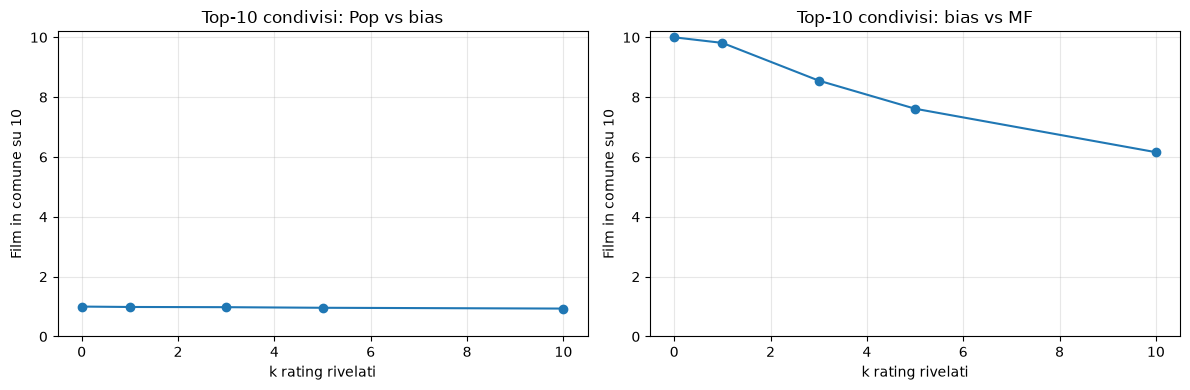

In [7]:
metrics=['user_factor_norm','sd_item_bias','sd_personal','personal_to_bias_sd',
         'overlap_pop_bias','overlap_pop_full','overlap_bias_full',
         'n_zero_train_in_top10_mf','n_zero_train_in_top10_bias']
per_user=(analysis.groupby(['userId','k'],as_index=False)[metrics].mean())
summary=(per_user.groupby('k')[metrics].agg(['mean','median'])
         .round(4))
print('Macro per utente (repliche aggregate prima della media):')
display(summary)
print('Primo rating, k=1 (media sulle repliche/scenari):')
display(analysis[analysis.k==1].groupby('first_rating_type',as_index=False)
        [['overlap_pop_full','overlap_bias_full','personal_to_bias_sd']].mean().round(4))

summary_cover=(experimental_rankings.groupby(['model','k'])['movieId']
               .nunique().reset_index(name='n_film_distinti'))
summary_cover['coverage_pct']=100*summary_cover.n_film_distinti/len(ids)
display(summary_cover.pivot(index='k',columns='model',values='n_film_distinti'))

item_bias_spearman=(pd.Series(popularity_scores).rank()
                    .corr(pd.Series(mf.item_bias).rank()))
print(f'Correlazione di Spearman (ranking globale Popularity vs item_bias): {item_bias_spearman:.4f}')
fig,axs=plt.subplots(1,2,figsize=(12,4))
for name,ys,ax in [
  ('Top-10 condivisi: Pop vs bias', 'overlap_pop_bias',axs[0]),
  ('Top-10 condivisi: bias vs MF', 'overlap_bias_full',axs[1])
]:
    view=per_user.groupby('k')[ys].mean()
    ax.plot(view.index,view.values,marker='o')
    ax.set_title(name);ax.set_xlabel('k rating rivelati');ax.set_ylabel('Film in comune su 10')
    ax.set_ylim(0,10.2);ax.grid(alpha=.3)
plt.tight_layout();plt.show()

## 7. Controfattuale sulla validation: il fold-in aggiunge valore rispetto ai soli bias?

Questa sezione è **diagnostica e post-hoc**. Congeliamo prima le graduatorie (sezione 5), poi leggiamo **solo le 20 etichette nascoste A della validation** per calcolare NDCG@10, Recall@10 e Hit Rate@10, con la stessa definizione binaria del notebook 02. Non confrontiamo metriche del test, non facciamo tuning e non modifichiamo i ranking ufficiali.

Se `mf_only_item_bias` supera `mf_full_foldin`, non significa automaticamente che il modello MF sia errato: può significare che il contributo personale aggiunge rumore in questo protocollo. Se accade il contrario, il fold-in può essere utile anche se MF resta inferiore a Popularity.

In [8]:
fixed = pd.read_csv(PRIVATE/'private_fixed_gt.csv')
assert {'scenario_id','movieId','rating'}.issubset(fixed.columns)
fixed_positive = {
    str(sid):set(grp.loc[grp.rating>=POS_MIN,'movieId'].astype(int))
    for sid,grp in fixed.groupby('scenario_id')
}
owner = dict(zip(scenarios.scenario_id.astype(str),scenarios.userId.astype(int)))
metric_rows=[]
for (sid,k,model),grp in experimental_rankings.groupby(['scenario_id','k','model'],sort=True):
    positives=fixed_positive[str(sid)]
    ranked=grp.sort_values('rank').movieId.astype(int).to_numpy()
    n=len(positives)
    labels=np.array([float(int(mid) in positives) for mid in ranked])
    assert len(ranked)==TOP_K and not set(ranked)&set(visible_by_level.get((str(sid),int(k)),EMPTY_OBS).movieId)
    if n:
        discounts=np.log2(np.arange(2,TOP_K+2))
        ndcg=float(np.sum(labels/discounts)/np.sum(1/discounts[:min(n,TOP_K)]))
        recall=float(labels.sum()/n)
        hr=float(labels.any())
    else:
        ndcg=recall=hr=np.nan
    metric_rows.append({'scenario_id':sid,'userId':owner[str(sid)],'k':int(k),'model':model,
                        'ndcg@10':ndcg,'recall@10':recall,'hr@10':hr,'n_positive':n})
metrics_a=pd.DataFrame(metric_rows)
per_user_a=(metrics_a.groupby(['userId','model','k'],as_index=False)
            [['ndcg@10','recall@10','hr@10']].mean())
macro_a=(per_user_a.groupby(['model','k'],as_index=False)
         [['ndcg@10','recall@10','hr@10']].mean())
print('Solo VALIDATION, ground truth A (non test):')
display(macro_a.round(4))
print('Confronto NDCG@10 A per k:')
display(macro_a.pivot(index='k',columns='model',values='ndcg@10').round(4))

Solo VALIDATION, ground truth A (non test):


,model,k,ndcg@10,recall@10,hr@10
0,mf_full_foldin,0,0.0179,0.0126,0.1467
1,mf_full_foldin,1,0.0179,0.0126,0.1467
2,mf_full_foldin,3,0.0210,0.0147,0.1667
3,mf_full_foldin,5,0.0210,0.0168,0.1667
4,mf_full_foldin,10,0.0202,0.0176,0.1800
5,mf_only_item_bias,0,0.0179,0.0126,0.1467
6,mf_only_item_bias,1,0.0179,0.0126,0.1467
7,mf_only_item_bias,3,0.0179,0.0126,0.1467
8,mf_only_item_bias,5,0.0179,0.0126,0.1467
9,mf_only_item_bias,10,0.0180,0.0126,0.1467


Confronto NDCG@10 A per k:


model,mf_full_foldin,mf_only_item_bias,popularity
k,,,
0,0.0179,0.0179,0.0657
1,0.0179,0.0179,0.0677
3,0.0210,0.0179,0.0679
5,0.0210,0.0179,0.0680
10,0.0202,0.0180,0.0715


## 8. Esempi puntuali e salvataggio autonomo

Mostriamo scenari con personalizzazione più o meno incisiva e archiviamo **solo** gli output di questo esperimento nella sua directory. Se la spiegazione risulta convincente, potremo integrare in un secondo momento:

- un salvataggio dei pesi MF direttamente in `recommendation_02` (per evitare perfino il retraining minimo);
- i controlli di contributo personale in un modulo diagnostico riutilizzabile;
- eventualmente un fallback o una variante ibrida da **selezionare sulla validation e verificare su un test indipendente**.

Nessuna di queste modifiche viene applicata adesso.

In [9]:
print('Scenari con minor overlap tra bias e MF completa (k>0):')
display(analysis[analysis.k>0].sort_values(['overlap_bias_full','scenario_id']).head(MAX_DETAIL_ROWS))
print('Scenari con maggior overlap tra bias e MF completa (k>0):')
display(analysis[analysis.k>0].sort_values(['overlap_bias_full','scenario_id'],ascending=[False,True]).head(MAX_DETAIL_ROWS))

if SAVE_DIAGNOSTICS:
    EXPERIMENT.mkdir(parents=True,exist_ok=True)
    analysis.to_csv(EXPERIMENT/'mf_componenti_per_scenario.csv',index=False)
    experimental_rankings.to_csv(EXPERIMENT/'mf_ranking_controfattuali_validation.csv',index=False)
    summary_cover.to_csv(EXPERIMENT/'mf_copertura_catalogo.csv',index=False)
    metrics_a.to_csv(EXPERIMENT/'mf_metriche_validation_A_per_scenario.csv',index=False)
    macro_a.to_csv(EXPERIMENT/'mf_metriche_validation_A_macro.csv',index=False)
    (EXPERIMENT/'diagnostic_manifest.json').write_text(json.dumps({
        'protocol_id':PROTOCOL_ID,'split':DIAGNOSTIC_SPLIT,
        'mf_fold_reg_selected':FOLD_REG,'train_sha256':cache_signature['train_sha256'],
        'model_state_source':'isolated_cache_or_identical_training',
        'official_results_modified':False,
        'analysis_scope':'exploratory post-hoc; validation A for counterfactuals; test only for label-free reproduction check',
    },ensure_ascii=False,indent=2),encoding='utf8')
    print('Output diagnostici:',EXPERIMENT)

Scenari con minor overlap tra bias e MF completa (k>0):


,scenario_id,userId,k,first_rating_type,user_bias,user_factor_norm,sd_item_bias,sd_personal,personal_to_bias_sd,overlap_bias_full,overlap_pop_bias,overlap_pop_full,n_zero_train_in_top10_mf,n_zero_train_in_top10_bias
379,validation_u384_r0,384,10,negativo,-0.488742,1.358074,0.272977,0.096097,0.352034,0,1,3,0,0
284,validation_u287_r2,287,10,intermedio,-0.847321,1.544157,0.272931,0.104688,0.383569,1,1,4,0,0
359,validation_u343_r2,343,10,positivo,-0.300223,0.981777,0.272628,0.069019,0.253162,1,1,4,0,0
638,validation_u572_r1,572,5,positivo,-0.206305,0.858010,0.273036,0.058524,0.214345,2,1,4,0,0
729,validation_u8_r1,8,10,positivo,-0.306986,0.981729,0.272791,0.070659,0.259022,2,1,3,0,0
213,validation_u264_r0,264,5,negativo,0.349117,0.930453,0.273034,0.064166,0.235010,3,1,0,0,0
229,validation_u267_r0,267,10,positivo,-0.170272,1.521442,0.272721,0.101011,0.370382,3,1,1,0,0
339,validation_u33_r1,33,10,intermedio,0.343457,0.789796,0.272878,0.051922,0.190274,3,0,3,0,0
354,validation_u343_r1,343,10,positivo,-0.401002,0.781962,0.272776,0.054034,0.198090,3,1,5,0,0
384,validation_u384_r1,384,10,negativo,-0.605551,1.247228,0.273129,0.083508,0.305743,3,1,3,0,0


Scenari con maggior overlap tra bias e MF completa (k>0):


,scenario_id,userId,k,first_rating_type,user_bias,user_factor_norm,sd_item_bias,sd_personal,personal_to_bias_sd,overlap_bias_full,overlap_pop_bias,overlap_pop_full,n_zero_train_in_top10_mf,n_zero_train_in_top10_bias
1,validation_u101_r0,101,1,intermedio,0.036307,0.002971,0.273053,0.000195,0.000713,10,1,1,0,0
6,validation_u101_r1,101,1,positivo,0.213648,0.019157,0.273089,0.001285,0.004707,10,1,1,0,0
11,validation_u101_r2,101,1,intermedio,-0.205254,0.019344,0.273095,0.001264,0.004629,10,1,1,0,0
16,validation_u121_r0,121,1,intermedio,-0.352724,0.049414,0.273102,0.003452,0.012642,10,1,1,0,0
21,validation_u121_r1,121,1,intermedio,-0.551912,0.051614,0.273091,0.003539,0.012959,10,1,1,0,0
26,validation_u121_r2,121,1,positivo,0.321487,0.032717,0.273099,0.002300,0.008421,10,1,1,0,0
36,validation_u129_r1,129,1,positivo,0.266903,0.027572,0.273011,0.001931,0.007072,10,1,1,0,0
37,validation_u129_r1,129,3,positivo,0.288809,0.192645,0.272977,0.013105,0.048008,10,1,1,0,0
38,validation_u129_r1,129,5,positivo,0.474044,0.303357,0.272981,0.019615,0.071854,10,1,1,0,0
39,validation_u129_r1,129,10,positivo,0.558976,0.383487,0.272913,0.025050,0.091788,10,1,1,0,0


Output diagnostici: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_protocol/rs_coldstart_full/evaluations/mf_foldin_diagnostic


## 9. Guida alla lettura dei risultati

| Esito diagnostico | Interpretazione **supportabile** | Passo successivo possibile |
|---|---|---|
| Top-10 bias vs Popularity molto diverse, ma bias vs MF quasi uguali | Il calo a `k=1` può dipendere soprattutto dal cambio di **baseline globale** | Valutare un fallback Popularity più coerente, *solo in un esperimento successivo* |
| Bias vs MF molto diverse, `personal_to_bias_sd` non trascurabile | Il fold-in **personalizza davvero**, ma potrebbe farlo in modo poco informativo | Verificare qualità dei fattori/numero di rating; non assumere insufficienza di personalizzazione |
| MF completa migliora rispetto a soli bias sulla validation | Esiste valore incrementale dei fattori personali nonostante i risultati assoluti | Tenere separati vantaggio personale e problema dei rating mancanti |
| Item senza rating training nei ranking MF | Item con fattori `Q` non appresi possono ricevere score arbitrari | Valutare un fallback per `train_n=0`, senza cambiare i ranking ufficiali |

**Limiti**: il valore di `k` cambia i rating disponibili al fold-in; l'overlap non equivale ad accuratezza; una buona performance sui giudizi osservati è condizionata al bias di osservazione MovieLens. Lo stesso test non va usato per giustificare tuning introdotto a posteriori.